# 02 Exploratory analysis

Week 3. No model and no predictions. This notebook answers five questions about the cleaned 40,000-row table in `data/processed/clean.csv`.

- Cleaning stays in `notebooks/01_cleaning.ipynb`. Nothing is recoded here.
- Class order, colors, and survey-weight helpers come from `src/diabetes_risk/describe.py`.
- The longer age, BMI, and exercise comparison is in `notebooks/02_relationships.ipynb`. This notebook adds the plots that question list asks for.
- Figures are saved under `reports/figures/`. The last cell names the three for the final slides.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from diabetes_risk.describe import CLASS_COLORS, CLASS_ORDER, weighted_mean, weighted_share

FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": "#0b0b0b",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "figure.dpi": 110,
})

df = pd.read_csv(ROOT / "data" / "processed" / "clean.csv")
df["any_exercise"] = df["any_exercise"].map({True: True, False: False, "True": True, "False": False})
df.shape

(40000, 14)

**How to read the weights.** The sample was drawn stratified on the target, and only from states that asked the sugary-soda question (see `reports/contract.md`). Weighted means describe each class within itself. The class counts below are the modeling sample, not national prevalence.

## 1. How is the target distributed?

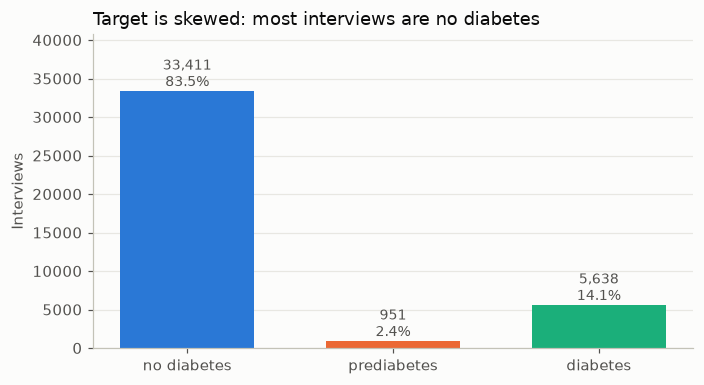

target
no_diabetes    83.5
prediabetes     2.4
diabetes       14.1
Name: count, dtype: float64

In [2]:
counts = df["target"].value_counts().reindex(CLASS_ORDER)
shares = 100 * counts / counts.sum()
labels = [c.replace("_", " ") for c in CLASS_ORDER]

fig, ax = plt.subplots(figsize=(6.5, 3.6))
bars = ax.bar(labels, counts, color=[CLASS_COLORS[c] for c in CLASS_ORDER], width=0.65)
for bar, n, share in zip(bars, counts, shares):
    ax.text(
        bar.get_x() + bar.get_width() / 2, bar.get_height(),
        f"{n:,.0f}\n{share:.1f}%", ha="center", va="bottom", fontsize=9, color="#52514e",
    )
ax.set_ylim(0, counts.max() * 1.22)
ax.set_ylabel("Interviews")
ax.set_title("Target is skewed: most interviews are no diabetes", loc="left")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIGURES / "eda_target.png", dpi=150)
plt.show()
shares.round(1)

The target is skewed. Of 40,000 interviews, 33,411 (83.5%) have no diabetes, 5,638 (14.1%) have diabetes, and 951 (2.4%) have prediabetes. Accuracy would reward a model that always says no diabetes, which is why the contract uses macro F1.

## 2. How are the three main variables distributed?

Age, BMI, and sugary drinks. Exercise is yes or no, so it is compared against the target in the next section instead of as a histogram.

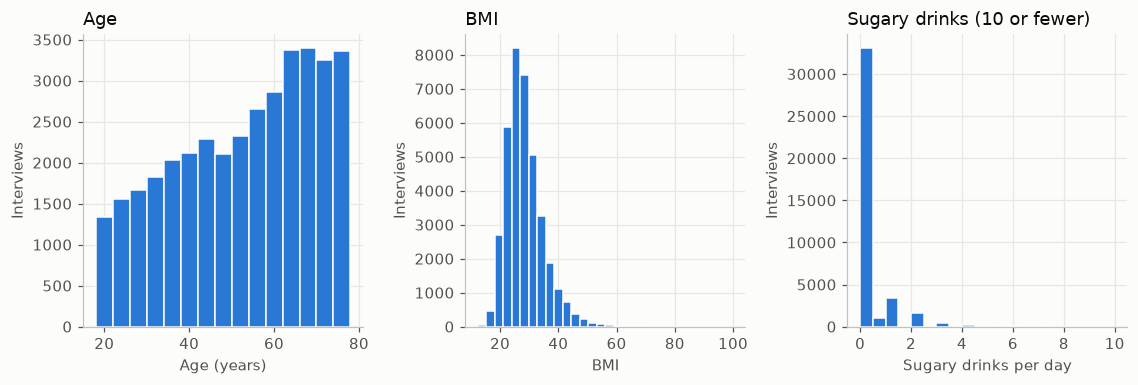

Age median 58, min 18, max 80
BMI median 27.4, min 12.4, max 99.8, missing 2,382
BMI equal to 0: 0    weight equal to 0: 0
Sugary drinks equal to 0: 18,609 (46.5%)    above 10 a day: 86


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.6))

axes[0].hist(df["age"], bins=np.arange(18, 82, 4), color="#2a78d6", edgecolor="#fcfcfb")
axes[0].set_xlabel("Age (years)")
axes[0].set_title("Age", loc="left")

bmi = df["bmi"].dropna()
axes[1].hist(bmi, bins=30, color="#2a78d6", edgecolor="#fcfcfb")
axes[1].set_xlabel("BMI")
axes[1].set_title("BMI", loc="left")

sugar = df.loc[df["sugar_drinks"] <= 10, "sugar_drinks"]
axes[2].hist(sugar, bins=20, color="#2a78d6", edgecolor="#fcfcfb")
axes[2].set_xlabel("Sugary drinks per day")
axes[2].set_title("Sugary drinks (10 or fewer)", loc="left")

for ax in axes:
    ax.set_ylabel("Interviews")
fig.tight_layout()
fig.savefig(FIGURES / "eda_histograms.png", dpi=150)
plt.show()

print(f"Age median {df['age'].median():.0f}, min {df['age'].min():.0f}, max {df['age'].max():.0f}")
print(f"BMI median {bmi.median():.1f}, min {bmi.min():.1f}, max {bmi.max():.1f}, missing {int(df['bmi'].isna().sum()):,}")
print(f"BMI equal to 0: {int((df['bmi'] == 0).sum())}    weight equal to 0: {int((df['weight_kg'] == 0).sum())}")
print(
    f"Sugary drinks equal to 0: {int((df['sugar_drinks'] == 0).sum()):,} "
    f"({100 * (df['sugar_drinks'] == 0).mean():.1f}%)    above 10 a day: {int((df['sugar_drinks'] > 10).sum())}"
)

Age is centered at 58 (range 18 to 80) with a tall right edge, BMI is centered at 27.4 and skewed right up to 99.8, and 46.5% of sugary-drink answers are a real zero that means never (that panel stops at 10 a day; 86 people are above it). There are no impossible zeros: BMI and weight never equal 0 (lowest BMI is 12.4), and the 2,382 missing BMIs were blank in the raw file rather than stored as 0.

## 3. Which variable is related to the target?

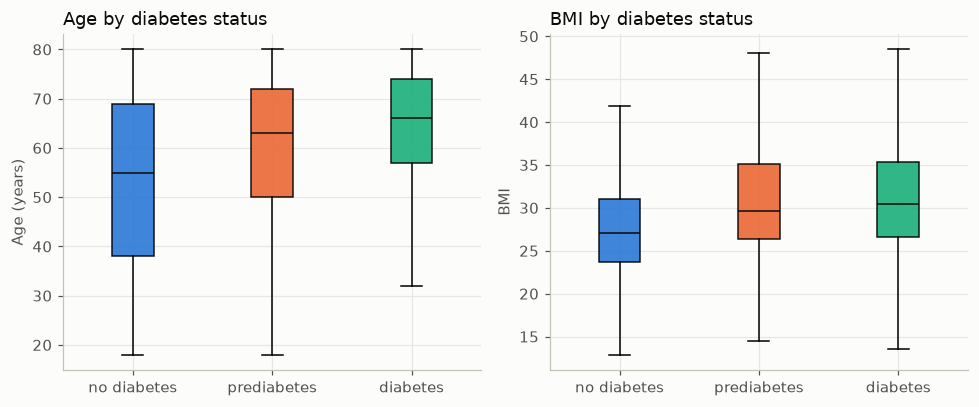

no_diabetes   age  47.1  bmi 27.9  sugar/day 0.42  exercise 81.4%
prediabetes   age  57.5  bmi 31.0  sugar/day 0.47  exercise 66.8%
diabetes      age  60.5  bmi 31.8  sugar/day 0.28  exercise 68.2%


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, col, ylabel in zip(axes, ["age", "bmi"], ["Age (years)", "BMI"]):
    groups = [df.loc[df["target"] == cls, col].dropna() for cls in CLASS_ORDER]
    boxes = ax.boxplot(
        groups, showfliers=False, patch_artist=True, medianprops={"color": "#0b0b0b"},
    )
    for patch, cls in zip(boxes["boxes"], CLASS_ORDER):
        patch.set_facecolor(CLASS_COLORS[cls])
        patch.set_alpha(0.9)
    ax.set_xticks([1, 2, 3], [c.replace("_", " ") for c in CLASS_ORDER])
    ax.set_ylabel(ylabel)
axes[0].set_title("Age by diabetes status", loc="left")
axes[1].set_title("BMI by diabetes status", loc="left")
fig.tight_layout()
fig.savefig(FIGURES / "eda_by_class.png", dpi=150)
plt.show()

for cls in CLASS_ORDER:
    g = df[df["target"] == cls]
    w = g["survey_weight"]
    print(
        f"{cls:12}  age {weighted_mean(g['age'], w):5.1f}  "
        f"bmi {weighted_mean(g['bmi'], w):4.1f}  "
        f"sugar/day {weighted_mean(g['sugar_drinks'], w):4.2f}  "
        f"exercise {100 * weighted_share(g['any_exercise'], w):4.1f}%"
    )

Age and BMI both rise across the three classes: weighted mean age is 47.1, 57.5, and 60.5 years, and weighted mean BMI is 27.9, 31.0, and 31.8. Sugary drinks do not separate the classes (0.42, 0.47, and 0.28 a day); exercise does, at 81.4% with no diabetes against 66.8% with prediabetes and 68.2% with diabetes.

## 4. Is there a strong correlation between variables?

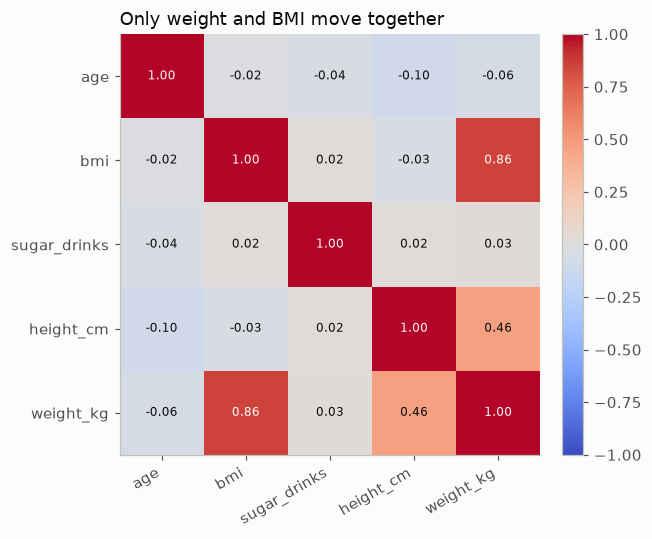

In [5]:
cols = ["age", "bmi", "sugar_drinks", "height_cm", "weight_kg"]
corr = df[cols].corr()

fig, ax = plt.subplots(figsize=(6.2, 5))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=30, ha="right")
ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        value = corr.iloc[i, j]
        ink = "#fcfcfb" if abs(value) >= 0.7 else "#0b0b0b"
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8, color=ink)
ax.grid(False)
ax.set_title("Only weight and BMI move together", loc="left")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(FIGURES / "eda_correlation.png", dpi=150)
plt.show()

The only strong pair is weight and BMI (0.86). Height's correlation with BMI is -0.03, so the redundant column is weight, not height. The model already uses BMI and keeps height and weight descriptive-only; putting weight in as well would repeat BMI.

## 5. What showed up that the summary stats hide?

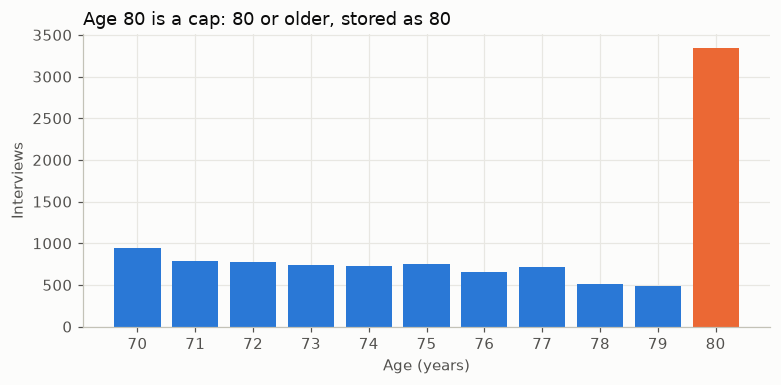

Age 79: 490    age 80: 3,342
Share coded 80: 8.4%


In [6]:
counts_by_age = df["age"].value_counts().sort_index()
tail = counts_by_age.loc[70:80]

fig, ax = plt.subplots(figsize=(7.2, 3.6))
colors = ["#2a78d6" if age < 80 else "#eb6834" for age in tail.index]
ax.bar(tail.index.astype(int).astype(str), tail.values, color=colors, width=0.8)
ax.set_xlabel("Age (years)")
ax.set_ylabel("Interviews")
ax.set_title("Age 80 is a cap: 80 or older, stored as 80", loc="left")
fig.tight_layout()
fig.savefig(FIGURES / "eda_age_cap.png", dpi=150)
plt.show()

print(f"Age 79: {int(counts_by_age.loc[79]):,}    age 80: {int(counts_by_age.loc[80]):,}")
print(f"Share coded 80: {100 * counts_by_age.loc[80] / len(df):.1f}%")

The tall right edge on the age histogram is one code, not a crowd of people who are exactly 80. BRFSS stores 80 or older as 80, so 3,342 interviews (8.4%) sit on that code, against 490 at age 79. A later model that treats 80 as exactly 80 years will understate how old that group is.

## Figures for the final slides

`reports/figures/eda_target.png`, `reports/figures/eda_by_class.png`, and `reports/figures/eda_age_cap.png`.

No model is fit here. If a later plot shows a cleaning error, fix it in `notebooks/01_cleaning.ipynb` and regenerate `clean.csv` rather than patching it in this notebook.